In [5]:
# importing the libraries
get_ipython().system('pip install kagglehub')


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [7]:
# importing the libraries
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [8]:
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

#Vamos utilizar um dataset para análise da possibilidade da profissão ser automatizada na área de programação
## A atividade consiste em explicar o porquê de termos determinadas previsões
### Você pode importar outro modelo o sklearn como XBOOST, SVM para poder comparar quantitativamente a eficiência, mas o objetivo é realizar a interpretação dos resultados com LIME e SHAP

In [13]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("khushikyad001/ai-impact-on-jobs-2030")

print("Path to dataset files:", path)

Path to dataset files: /Users/jwcunha/.cache/kagglehub/datasets/khushikyad001/ai-impact-on-jobs-2030/versions/1


In [17]:
import os      
df = pd.read_csv(os.path.join(path, "AI_Impact_on_Jobs_2030.csv"))

In [18]:
df.head()

,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,Skill_6,Skill_7,Skill_8,Skill_9,Skill_10
0,Security Guard,45795,28,Master's,0.18,1.28,0.85,High,0.45,0.10,0.46,0.33,0.14,0.65,0.06,0.72,0.94,0.00
1,Research Scientist,133355,20,PhD,0.62,1.11,0.05,Low,0.02,0.52,0.40,0.05,0.97,0.23,0.09,0.62,0.38,0.98
2,Construction Worker,146216,2,High School,0.86,1.18,0.81,High,0.01,0.94,0.56,0.39,0.02,0.23,0.24,0.68,0.61,0.83
3,Software Engineer,136530,13,PhD,0.39,0.68,0.60,Medium,0.43,0.21,0.57,0.03,0.84,0.45,0.40,0.93,0.73,0.33
4,Financial Analyst,70397,22,High School,0.52,1.46,0.64,Medium,0.75,0.54,0.59,0.97,0.61,0.28,0.30,0.17,0.02,0.42


In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
from sklearn.preprocessing import  OrdinalEncoder
category=[ 'High School', "Bachelor's","Master's", 'PhD']
ordinal=OrdinalEncoder(categories=[category])
df['Education_Level']=ordinal.fit_transform(df[['Education_Level']])

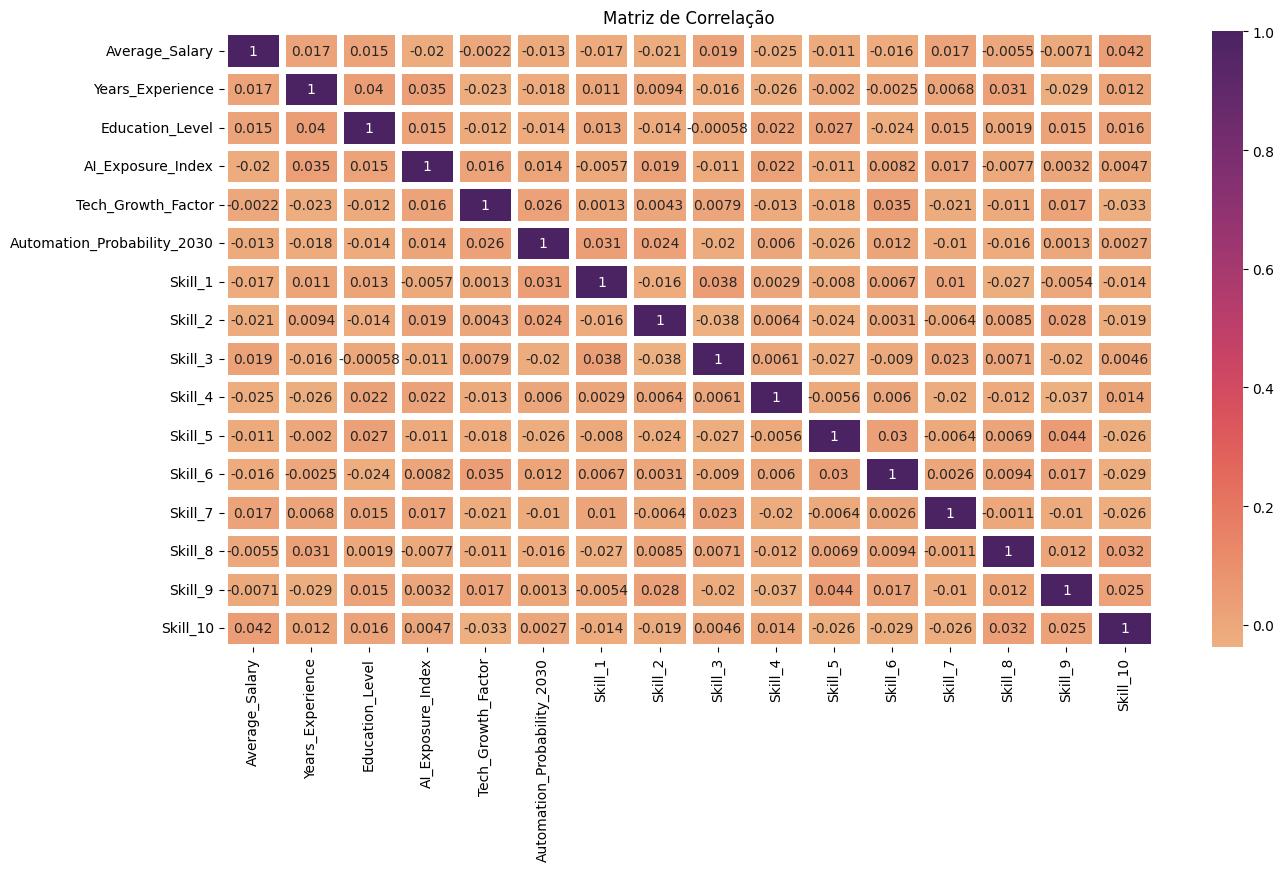

In [39]:
plt.figure(figsize=(15, 8))
sns.heatmap(df.corr(numeric_only=True),annot=True,linewidth=5,cmap='flare')
plt.title('Matriz de Correlação')
plt.show()

#Treinar o modelo
### Treine o modelo com o objetivo de quão está arriscado a carreira da pessoa com determinadas características (features)

#Separe os dados de treinamento

In [22]:
df.head()

,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,Skill_6,Skill_7,Skill_8,Skill_9,Skill_10
0,Security Guard,45795,28,2.0,0.18,1.28,0.85,High,0.45,0.10,0.46,0.33,0.14,0.65,0.06,0.72,0.94,0.00
1,Research Scientist,133355,20,3.0,0.62,1.11,0.05,Low,0.02,0.52,0.40,0.05,0.97,0.23,0.09,0.62,0.38,0.98
2,Construction Worker,146216,2,0.0,0.86,1.18,0.81,High,0.01,0.94,0.56,0.39,0.02,0.23,0.24,0.68,0.61,0.83
3,Software Engineer,136530,13,3.0,0.39,0.68,0.60,Medium,0.43,0.21,0.57,0.03,0.84,0.45,0.40,0.93,0.73,0.33
4,Financial Analyst,70397,22,0.0,0.52,1.46,0.64,Medium,0.75,0.54,0.59,0.97,0.61,0.28,0.30,0.17,0.02,0.42


In [23]:
x=df.drop('Automation_Probability_2030',axis=1)
y=df['Automation_Probability_2030']

In [24]:
x.head()

,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Risk_Category,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,Skill_6,Skill_7,Skill_8,Skill_9,Skill_10
0,Security Guard,45795,28,2.0,0.18,1.28,High,0.45,0.10,0.46,0.33,0.14,0.65,0.06,0.72,0.94,0.00
1,Research Scientist,133355,20,3.0,0.62,1.11,Low,0.02,0.52,0.40,0.05,0.97,0.23,0.09,0.62,0.38,0.98
2,Construction Worker,146216,2,0.0,0.86,1.18,High,0.01,0.94,0.56,0.39,0.02,0.23,0.24,0.68,0.61,0.83
3,Software Engineer,136530,13,3.0,0.39,0.68,Medium,0.43,0.21,0.57,0.03,0.84,0.45,0.40,0.93,0.73,0.33
4,Financial Analyst,70397,22,0.0,0.52,1.46,Medium,0.75,0.54,0.59,0.97,0.61,0.28,0.30,0.17,0.02,0.42


In [25]:
y.head()

0    0.85
1    0.05
2    0.81
3    0.60
4    0.64
Name: Automation_Probability_2030, dtype: float64

In [26]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=101)

In [27]:
train=pd.concat([X_train,y_train],axis=1)
columns=['Job_Title','Risk_Category']
for col in columns:
  mean=train.groupby(col)['Automation_Probability_2030'].mean()
  global_mean=train['Automation_Probability_2030'].mean()
  X_train[col]=X_train[col].map(mean).fillna(global_mean)
  X_test[col]=X_test[col].map(mean).fillna(global_mean)

In [28]:
rf = RandomForestRegressor()

In [29]:
rf.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [30]:
rf.predict(X_test)

array([0.5137, 0.506 , 0.8625, 0.5176, 0.8409, 0.8079, 0.4733, 0.4927,
       0.173 , 0.1827, 0.4935, 0.5177, 0.5057, 0.486 , 0.5594, 0.5312,
       0.5729, 0.8394, 0.4791, 0.4964, 0.8018, 0.8183, 0.4931, 0.5172,
       0.4734, 0.5257, 0.1864, 0.5231, 0.8257, 0.4963, 0.8547, 0.5111,
       0.5224, 0.5164, 0.876 , 0.2059, 0.4765, 0.484 , 0.192 , 0.4946,
       0.1832, 0.1575, 0.4938, 0.8072, 0.8145, 0.1907, 0.185 , 0.494 ,
       0.493 , 0.5018, 0.8378, 0.5026, 0.1631, 0.1694, 0.5213, 0.8546,
       0.8203, 0.8282, 0.5189, 0.4983, 0.8733, 0.8217, 0.8363, 0.8503,
       0.1908, 0.8446, 0.1584, 0.4788, 0.8004, 0.4834, 0.1758, 0.5132,
       0.5108, 0.8201, 0.8225, 0.8639, 0.8381, 0.1692, 0.1733, 0.1657,
       0.5219, 0.1726, 0.4947, 0.5399, 0.5204, 0.529 , 0.8383, 0.4866,
       0.5125, 0.8309, 0.4697, 0.8409, 0.4992, 0.5354, 0.4769, 0.5067,
       0.8277, 0.5019, 0.1784, 0.8124, 0.5181, 0.1554, 0.7989, 0.8103,
       0.1806, 0.2028, 0.2046, 0.82  , 0.833 , 0.5416, 0.8482, 0.4979,
      

## Instale SHAP E LIME



In [32]:
get_ipython().system('pip install shap')
get_ipython().system('pip install lime')


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [33]:
import shap

# Exemplo com 500 instâncias para teste
X_train_sample = X_train.sample(500, random_state=42)

explainer = shap.TreeExplainer(rf, X_train_sample)


X_test_sample = X_test.sample(500, random_state=42)


shap_values = explainer.shap_values(X_test_sample)

print("SHAP inicializado e valores calculados ")

Background dataset has 500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=500 when initializing the masker.
 93%|=================== | 464/500 [00:14<00:01]       

SHAP inicializado e valores calculados 


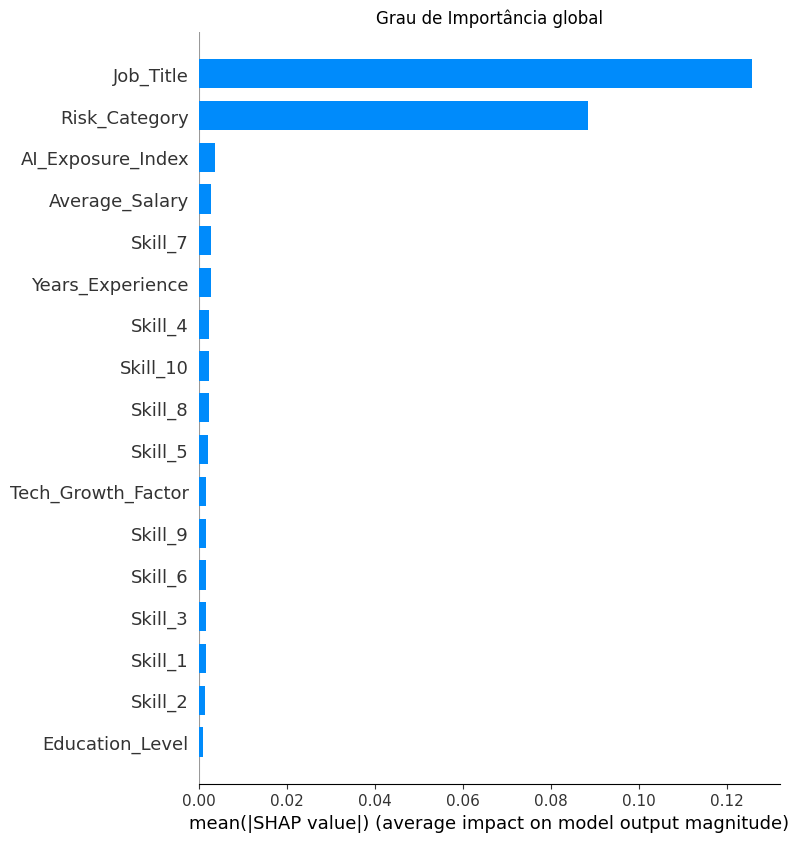

In [34]:
shap.summary_plot(shap_values, X_test_sample, plot_type="bar", show=False)
plt.title("Grau de Importância global")
plt.show()

Plotagem de Importância das Variáveis - Interpretação Global


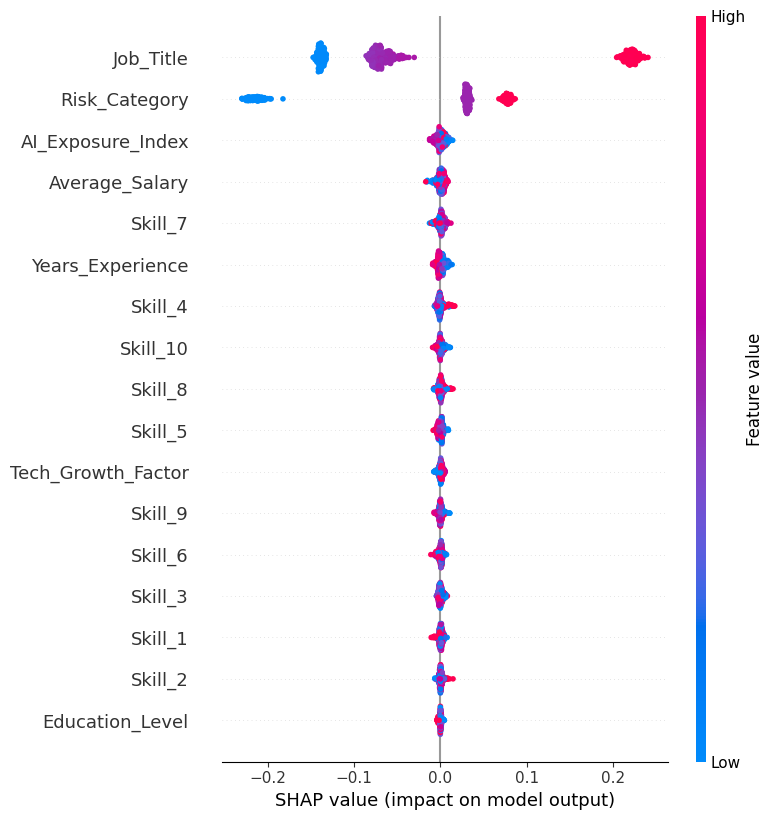

In [35]:
print("Plotagem de Importância das Variáveis - Interpretação Global")
figure = plt.figure()
shap.summary_plot(shap_values, X_test_sample)

In [40]:
from lime.lime_tabular import LimeTabularExplainer

feature_names = X_train.columns.tolist()


lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=['Automation_Probability'], # nome da variável alvo
    mode='regression'
)

print("LIME: explicador inicializado")

LIME: explicador inicializado


In [42]:
random_instance_idx = 0
instance_to_explain = X_test_sample.iloc[random_instance_idx].values

# Generate explanation for the instance
lime_explanation = lime_explainer.explain_instance(
    data_row=instance_to_explain,
    predict_fn=rf.predict,
    num_features=5
)

print(f"LIME: explicação geradada a partir das instâncias de modo randômico{random_instance_idx}.")
print("Top features para essa predição")
for feature, weight in lime_explanation.as_list():
    print(f"- {feature}: {weight:.4f}")

LIME: explicação geradada a partir das instâncias de modo randômico0.
Top features para essa predição
- Job_Title <= 0.48: -0.1278
- Risk_Category <= 0.50: -0.1097
- 0.50 < AI_Exposure_Index <= 0.74: -0.0112
- Tech_Growth_Factor <= 0.74: -0.0104
- Skill_2 <= 0.24: -0.0085


/Users/jwcunha/.pyenv/versions/3.12.9/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [51]:
# lime_explanation.show_in_notebook(show_table=True, show_all=False)
from IPython.display import display, HTML
display(HTML(lime_explanation.as_html(show_table=True, show_all=False)))
print("Explicação visual do LIME.")

Explicação visual do LIME.


#Questões

De acordo com a matrix de correlação, faça dois experimentos:


1.   Exclua dois tipos skills e analise o resultado do lime, bem como o predict
2.   Exclua o AI_Exposure_Index e o Years_Experience

após isso, discuta os resultados e avalie o melhor após da run nas células do LIME e SHAP

